# Projeto 1 – C11/C111: Travel And Tourism

Análise exploratória do dataset *Travel And Tourism* usando apenas **NumPy, Pandas e Matplotlib**.

As 10 perguntas estão ordenadas da mais para a menos relevante; as 5 primeiras são as da apresentação.

| # | Pergunta |
|---|---|
| 1 | Quais destinos geram mais receita? |
| 2 | Quais são os destinos turísticos mais procurados? |
| 3 | Quais são os principais motivos de cancelamento? |
| 4 | Quantos clientes estão insatisfeitos? |
| 5 | Qual o custo por viajante por noite em cada país? |
| 6 | Em quais meses ocorre o maior volume de viagens e reservas? |
| 7 | Onde se concentram os maiores custos de viagens concluídas? |
| 8 | Quais são os modos de transporte mais utilizados e como variam os custos? |
| 9 | Como gastos e duração variam entre viajantes individuais, duplas e grupos? |
| 10 | Que diferenças existem entre grupos com e sem crianças? |

**Observações sobre os dados**
- `Customer_Rating = 0` significa "sem avaliação" (viagem cancelada ou ainda não realizada); por isso, satisfação só é analisada em viagens concluídas.
- O dataset não informa a moeda dos valores.

## Carga dos dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dados = pd.read_csv('Travel And Tourism.csv', parse_dates=['Booking_Date', 'Travel_Date', 'Return_Date'])

dados['Custo_por_viajante'] = dados['Total_Trip_Cost'] / dados['Number_of_Travellers']
dados['Custo_viajante_noite'] = dados['Custo_por_viajante'] / dados['Number_of_Nights']

concluidas = dados[dados['Booking_Status'] == 'Completed']

print(dados.shape)
dados.head()


(1000, 31)


,Booking_ID,Booking_Date,Travel_Date,Return_Date,Customer_ID,Customer_Name,Customer_Age,Gender,Customer_City,Customer_Country,...,Booking_Status,Cancellation_Status,Cancellation_Reason,Discount_Amount,Customer_Rating,Customer_Review_Comment,Total_Trip_Cost,Transportation_Type,Custo_por_viajante,Custo_viajante_noite
0,1,2026-02-23,2026-04-18,2026-04-21,cust01,Kenzo Vaughn,18,Male,Dubai,United Arab Emirates,...,Completed,Not Cancelled,Not Applicable,12800,1.0,Poor service experience,115000,Flight,23000.000000,7666.666667
1,2,2025-05-30,2025-06-29,2025-07-02,cust02,Priya Carter,20,Female,Udaipur,India,...,Completed,Not Cancelled,Not Applicable,0,1.5,Poor service experience,56800,Train,14200.000000,4733.333333
2,3,2024-12-30,2025-03-14,2025-03-23,cust03,Elina Vaughn,31,Female,Dubai,United Arab Emirates,...,Completed,Not Cancelled,Not Applicable,74400,2.0,Several arrangements need improvement,669800,Flight,74422.222222,8269.135802
3,4,2026-06-17,2026-09-19,2026-09-26,cust04,Mei Ferraro,30,Male,Kathmandu,Nepal,...,Confirmed,Not Cancelled,Not Applicable,4500,0.0,Not yet travelled,84700,Flight,28233.333333,4033.333333
4,5,2025-03-21,2025-04-21,2025-04-24,cust05,Alina Desai,39,Female,Kuala Lumpur,Malaysia,...,Completed,Not Cancelled,Not Applicable,2800,3.6,Good overall experience,15600,Flight,15600.000000,5200.000000


## 1. Quais destinos geram mais receita?
Considera reservas concluídas e confirmadas (as que geram receita).

As 10 cidades com maior receita


,Cidade,Receita,Participação (%)
0,London,19922400,10.4
1,Malé,17153200,9.0
2,Paris,16265500,8.5
3,Dubai,12875400,6.7
4,Colombo,11991500,6.3
5,Bali,11794500,6.2
6,Singapore,10262400,5.4
7,Bangkok,7130900,3.7
8,Kathmandu,6778800,3.5
9,Mumbai,6333800,3.3


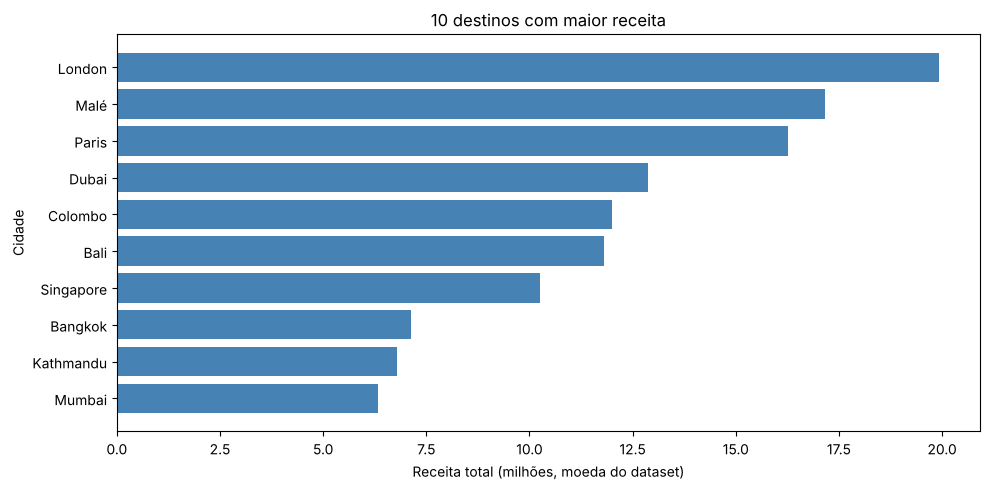

In [ ]:
pagas = dados[dados['Booking_Status'].isin(['Completed', 'Confirmed'])]

receita = pagas.groupby('Destination_City')['Total_Trip_Cost'].sum()
top_receita = receita.sort_values(ascending=False).head(10)

tabela_receita = pd.DataFrame({
    'Cidade': top_receita.index,
    'Receita': top_receita.values,
    'Participação (%)': (100 * top_receita.values / receita.sum()).round(1)
})

print('As 10 cidades com maior receita')
display(tabela_receita)

plt.figure(figsize=(10, 5))
plt.barh(top_receita.index, top_receita.values / 1e6, color='steelblue')
plt.gca().invert_yaxis()  # maior receita no topo

plt.title('10 destinos com maior receita')
plt.xlabel('Receita total (milhões, moeda do dataset)')
plt.ylabel('Cidade')
plt.tight_layout()
plt.show()


## 2. Quais são os destinos turísticos mais procurados pelos clientes?
Conta todas as reservas (inclusive canceladas), pois medem a procura.

As 11 cidades mais procuradas (top 10 com empates)


,Cidade,Quantidade
0,Colombo,49
1,Shimla,49
2,Rishikesh,45
3,Bali,44
4,Munnar,43
5,Dubai,42
6,Leh,42
7,Manali,42
8,Darjeeling,41
9,London,41


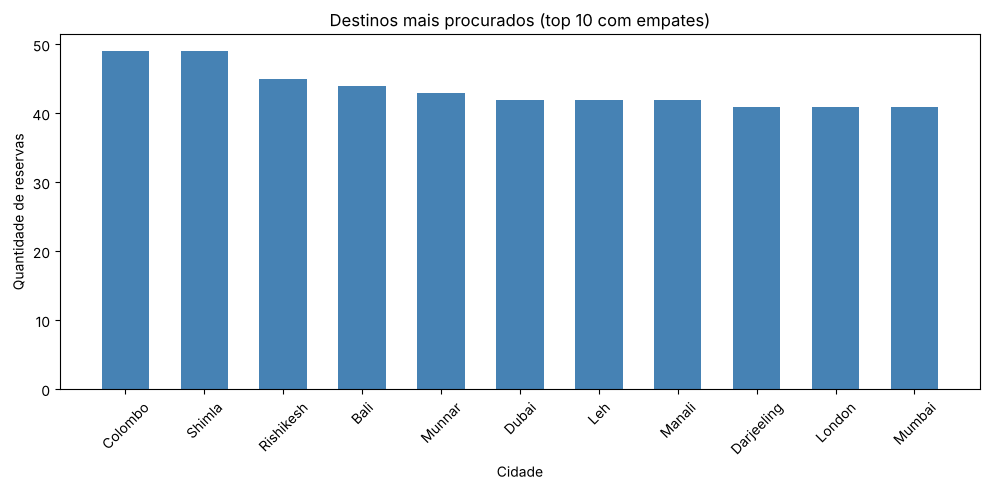

In [ ]:
top_destinos = dados.groupby('Destination_City')['Booking_ID'].count().nlargest(10, keep='all')

tabela_cidades = pd.DataFrame({
    'Cidade': top_destinos.index,
    'Quantidade': top_destinos.values
})

print(f'As {len(top_destinos)} cidades mais procuradas (top 10 com empates)')
display(tabela_cidades)

plt.figure(figsize=(10, 5))
plt.bar(top_destinos.index, top_destinos.values, color='steelblue', width=0.6)

plt.title('Destinos mais procurados (top 10 com empates)')
plt.xlabel('Cidade')
plt.ylabel('Quantidade de reservas')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 3. Quais são os principais motivos de cancelamento das reservas?

Taxa de cancelamento: 14.1% (141 de 1000 reservas)


,Motivo do cancelamento,Quantidade de cancelamentos
0,Family emergency,27
1,Transportation disruption,24
2,Visa issue,22
3,Budget constraints,21
4,Medical emergency,17
5,Work commitment,16
6,Change in travel plans,14


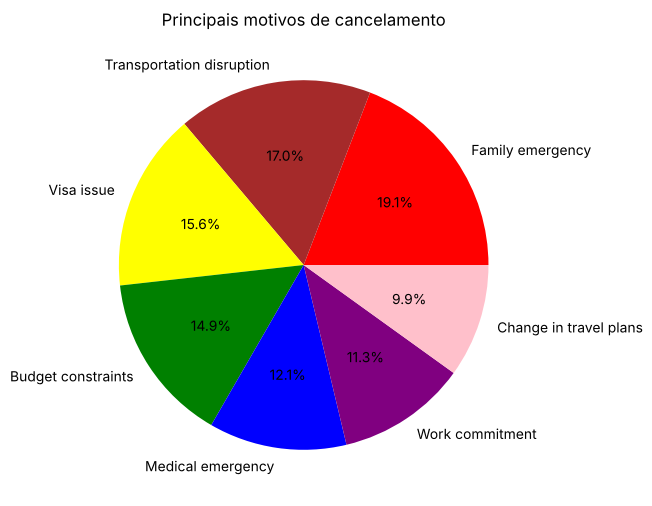

In [ ]:
# selecionando somente as reservas canceladas
cancelamentos = dados[dados['Cancellation_Status'] == 'Cancelled']

# contando os cancelamentos por motivo, do mais para o menos frequente
qtd_motivos = cancelamentos.groupby('Cancellation_Reason')['Booking_ID'].count()
qtd_motivos = qtd_motivos.sort_values(ascending=False)

tabela_cancelamento = pd.DataFrame({
    'Motivo do cancelamento': qtd_motivos.index,
    'Quantidade de cancelamentos': qtd_motivos.values
})

taxa = 100 * len(cancelamentos) / len(dados)
print(f'Taxa de cancelamento: {taxa:.1f}% ({len(cancelamentos)} de {len(dados)} reservas)')
display(tabela_cancelamento)

plt.figure(figsize=(6, 6))
plt.pie(qtd_motivos, labels=qtd_motivos.index, autopct='%1.1f%%', colors=['red', 'brown', 'yellow', 'green', 'blue', 'purple', 'pink'])

plt.title('Principais motivos de cancelamento')
plt.show()


## 4. Quantos clientes estão insatisfeitos (nota < 3)?
Apenas viagens concluídas (as únicas com nota).

Viagens avaliadas: 772
Nota média: 3.00
Clientes insatisfeitos (nota < 3): 50.3%


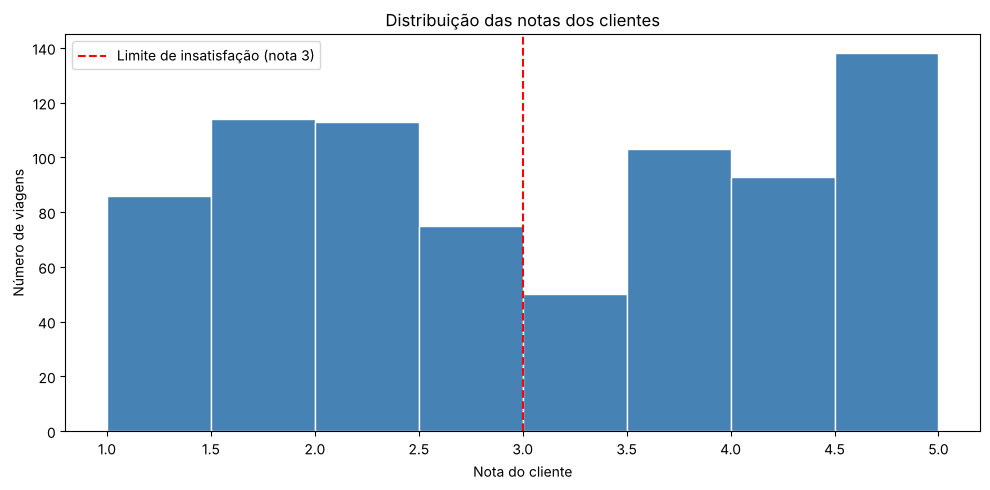

In [ ]:
# selecionando as notas das viagens concluídas
notas = concluidas['Customer_Rating']

# calculando o percentual de clientes com nota menor que 3
insatisfeitos = 100 * (notas < 3).mean()

print(f'Viagens avaliadas: {len(notas)}')
print(f'Nota média: {notas.mean():.2f}')
print(f'Clientes insatisfeitos (nota < 3): {insatisfeitos:.1f}%')

# criando o histograma; faixas de 0.5 porque as notas vão de 1.0 a 5.0 em passos de 0.1
plt.figure(figsize=(10, 5))
plt.hist(notas, bins=np.arange(1, 5.5, 0.5), color='steelblue', edgecolor='white')
plt.axvline(3, color='red', linestyle='--', label='Limite de insatisfação (nota 3)')

plt.title('Distribuição das notas dos clientes')
plt.xlabel('Nota do cliente')
plt.ylabel('Número de viagens')
plt.legend()
plt.tight_layout()
plt.show()


## 5. Qual o custo médio por viajante por noite em cada país de destino?

,País,Custo por viajante por noite
0,France,24553.0
1,United Kingdom,22254.0
2,Maldives,17546.0
3,United Arab Emirates,12991.0
4,Indonesia,11744.0
5,Singapore,11506.0
6,Thailand,9062.0
7,Sri Lanka,8520.0
8,Nepal,7152.0
9,India,5316.0


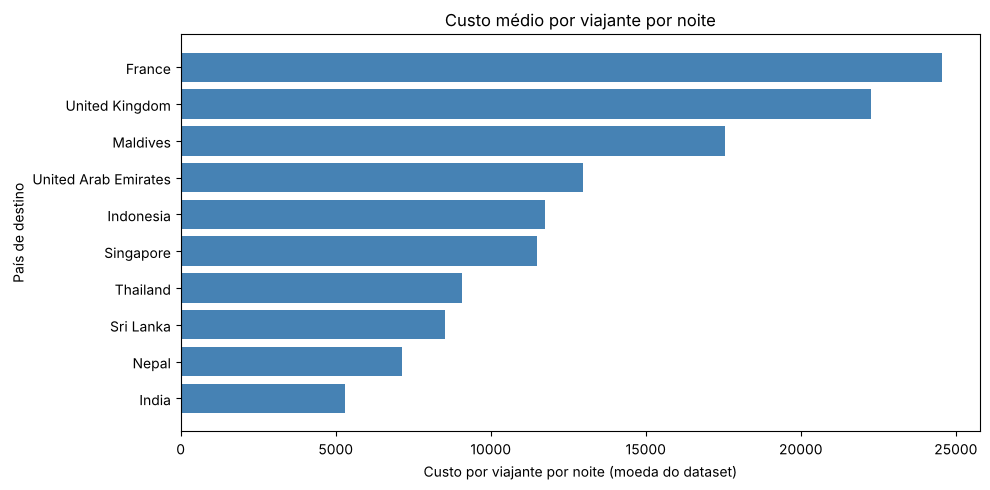

In [ ]:
# calculando o custo médio por viajante por noite de cada país
custo_noite = dados.groupby('Destination_Country')['Custo_viajante_noite'].mean()
custo_noite = custo_noite.sort_values(ascending=False)

tabela_custo = pd.DataFrame({
    'País': custo_noite.index,
    'Custo por viajante por noite': custo_noite.values.round(0)
})

display(tabela_custo)

plt.figure(figsize=(10, 5))
plt.barh(custo_noite.index, custo_noite.values, color='steelblue')
plt.gca().invert_yaxis()  # país mais caro no topo

plt.title('Custo médio por viajante por noite')
plt.xlabel('Custo por viajante por noite (moeda do dataset)')
plt.ylabel('País de destino')
plt.tight_layout()
plt.show()


## 6. Em quais meses ocorre o maior volume de viagens e reservas?

As reservas vão de jan/2024 a ago/2026: somar todos os anos faria jan–ago contarem 3 anos e
set–dez só 2, criando uma falsa queda no fim do ano. Por isso usamos só **2025**, único ano
com reservas e viagens completas nas duas pontas.

,Reservas por mês,Viagens por mês
Janeiro,29,26
Fevereiro,27,28
Março,38,27
Abril,27,27
Maio,32,45
Junho,27,19
Julho,40,36
Agosto,34,37
Setembro,26,30
Outubro,36,31


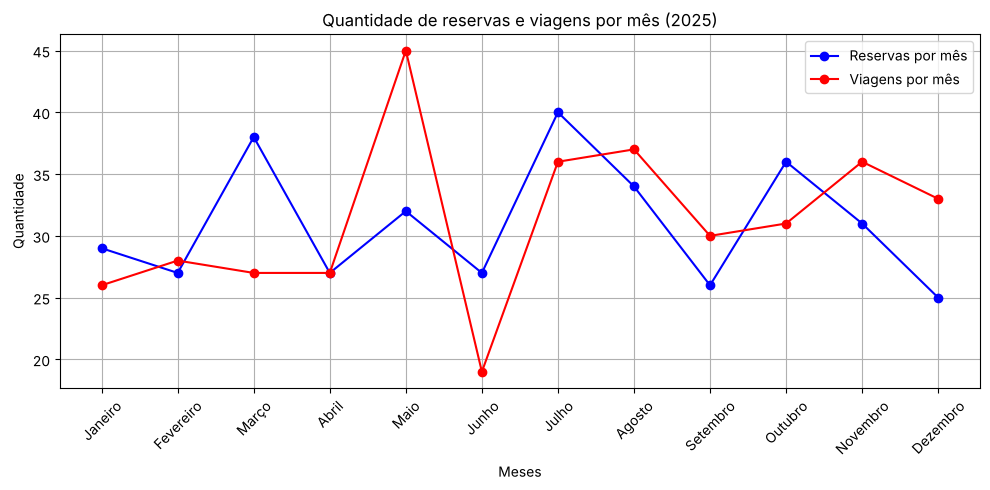

In [ ]:
# selecionando as reservas e as viagens de 2025
reservas_2025 = dados[dados['Booking_Date'].dt.year == 2025]
viagens_2025 = dados[dados['Travel_Date'].dt.year == 2025]

# contando reservas e viagens por mês
reservas_mes = reservas_2025.groupby(reservas_2025['Booking_Date'].dt.month)['Booking_ID'].count()
viagens_mes = viagens_2025.groupby(viagens_2025['Travel_Date'].dt.month)['Booking_ID'].count()

tabela_meses = pd.DataFrame({
    'Reservas por mês': reservas_mes,
    'Viagens por mês': viagens_mes
})

tabela_meses = tabela_meses.reindex(range(1, 13), fill_value=0)
tabela_meses.index = [
    'Janeiro', 'Fevereiro', 'Março', 'Abril',
    'Maio', 'Junho', 'Julho', 'Agosto',
    'Setembro', 'Outubro', 'Novembro', 'Dezembro'
]

display(tabela_meses)

plt.figure(figsize=(10, 5))
plt.plot(tabela_meses.index, tabela_meses['Reservas por mês'], color='blue', marker='o', label='Reservas por mês')
plt.plot(tabela_meses.index, tabela_meses['Viagens por mês'], color='red', marker='o', label='Viagens por mês')

plt.title('Quantidade de reservas e viagens por mês (2025)')
plt.xlabel('Meses')
plt.ylabel('Quantidade')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## 7. Onde se concentram os maiores custos de viagens concluídas?

,Viagens,Custo_total,Custo_medio
Destination_Country,,,
India,522,70023000,134144.0
Maldives,27,16421100,608189.0
United Kingdom,26,15635400,601362.0
France,20,12642300,632115.0
Sri Lanka,41,11590300,282690.0
United Arab Emirates,29,11108200,383041.0
Indonesia,29,10630900,366583.0
Singapore,21,9563800,455419.0
Thailand,31,7130900,230029.0


Custo total: 169991000


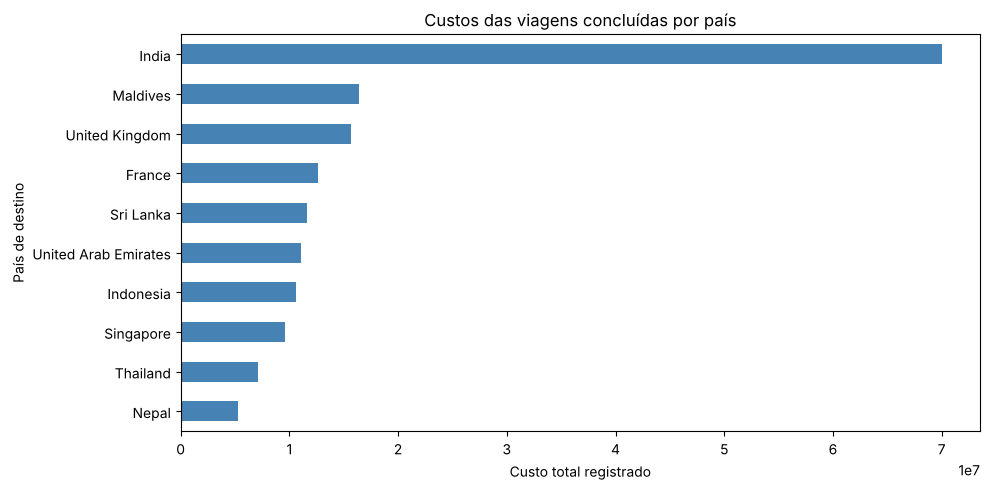

In [ ]:
# somando os custos das viagens concluídas por país
custos = concluidas.groupby('Destination_Country').agg(
    Viagens=('Booking_ID', 'size'),
    Custo_total=('Total_Trip_Cost', 'sum'),
    Custo_medio=('Total_Trip_Cost', 'mean')
).sort_values('Custo_total', ascending=False)

display(custos.round(0))
print('Custo total:', concluidas['Total_Trip_Cost'].sum())

custos['Custo_total'].sort_values().plot(kind='barh', figsize=(10, 5), color='steelblue')

plt.title('Custos das viagens concluídas por país')
plt.xlabel('Custo total registrado')
plt.ylabel('País de destino')
plt.tight_layout()
plt.show()


## 8. Quais são os modos de transporte mais utilizados e como variam os custos normalizados entre eles?

,Reservas,Custo_mediano
Transportation_Type,,
Flight,518,38136.11
Train,145,22050.00
Car,109,21637.50


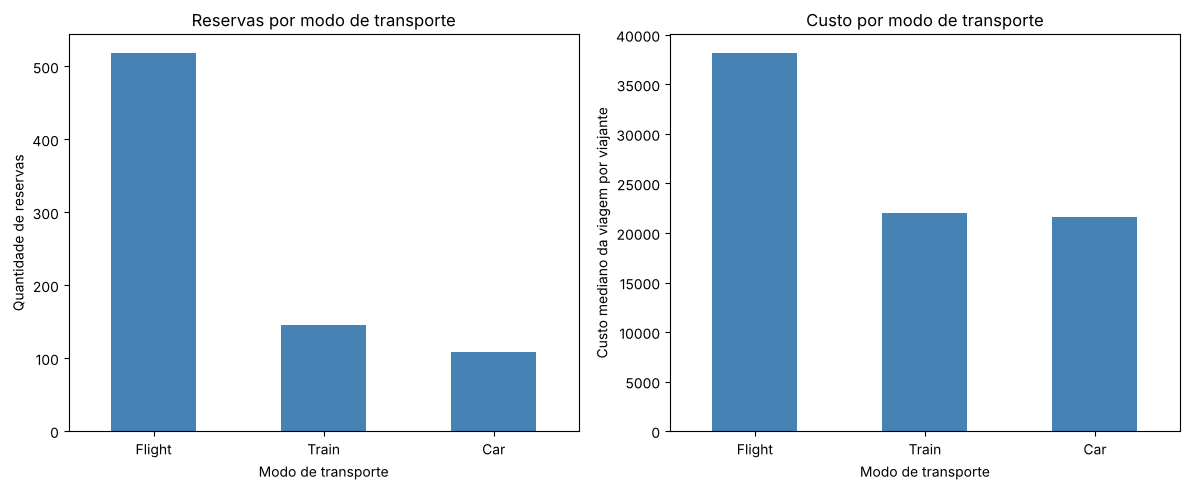

In [ ]:
# agrupando as viagens concluídas por modo de transporte
modos = concluidas.groupby('Transportation_Type').agg(
    Reservas=('Booking_ID', 'size'),
    Custo_mediano=('Custo_por_viajante', 'median')
).sort_values('Reservas', ascending=False)

display(modos.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

modos['Reservas'].plot(kind='bar', color='steelblue', ax=axes[0], rot=0)
axes[0].set_title('Reservas por modo de transporte')
axes[0].set_xlabel('Modo de transporte')
axes[0].set_ylabel('Quantidade de reservas')

modos['Custo_mediano'].plot(kind='bar', color='steelblue', ax=axes[1], rot=0)
axes[1].set_title('Custo por modo de transporte')
axes[1].set_xlabel('Modo de transporte')
axes[1].set_ylabel('Custo mediano da viagem por viajante')

plt.tight_layout()
plt.show()


## 9. Como os gastos e a duração das viagens variam entre viajantes individuais, duplas e grupos?

"Dupla" em vez de "Casal": 11 das 156 reservas com 2 viajantes incluem uma criança, então nem toda dupla é um casal.

Comparação entre os perfis de viajantes:


,Gasto médio por viagem,Duração média (noites)
Perfil,,
Dupla,77664.74,5.24
Família/Grupo,275057.42,5.40
Individual,58935.53,5.41


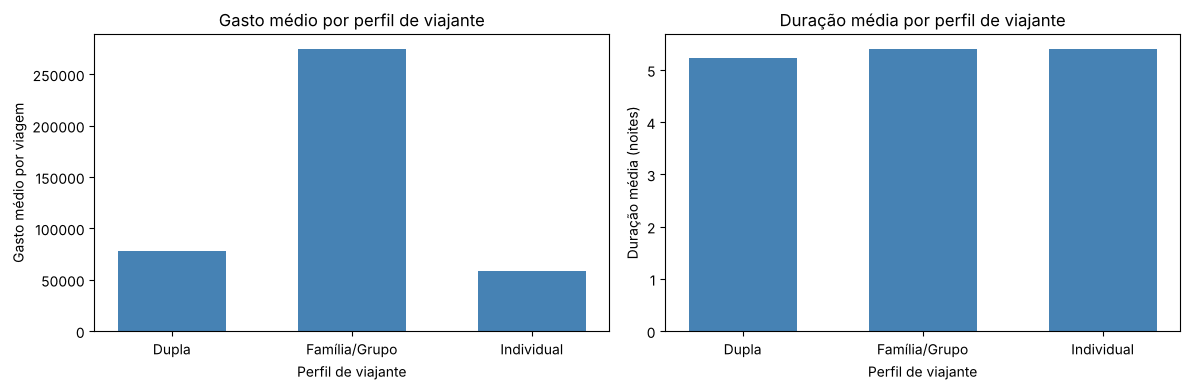

In [ ]:
# criando uma coluna para identificar o perfil dos viajantes
dados['Perfil'] = 'Família/Grupo'
dados.loc[dados['Number_of_Travellers'] == 1, 'Perfil'] = 'Individual'
dados.loc[dados['Number_of_Travellers'] == 2, 'Perfil'] = 'Dupla'

# calculando o gasto medio e a duracao media por perfil
grupo_viajantes = dados.groupby('Perfil')
media_gastos = grupo_viajantes['Total_Trip_Cost'].mean()
media_duracao = grupo_viajantes['Number_of_Nights'].mean()

tabela_viajantes = pd.DataFrame({
    'Gasto médio por viagem': media_gastos,
    'Duração média (noites)': media_duracao
})

print('Comparação entre os perfis de viajantes:')
display(tabela_viajantes.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(media_gastos.index, media_gastos.values, color='steelblue', width=0.6)
axes[0].set_title('Gasto médio por perfil de viajante')
axes[0].set_xlabel('Perfil de viajante')
axes[0].set_ylabel('Gasto médio por viagem')

axes[1].bar(media_duracao.index, media_duracao.values, color='steelblue', width=0.6)
axes[1].set_title('Duração média por perfil de viajante')
axes[1].set_xlabel('Perfil de viajante')
axes[1].set_ylabel('Duração média (noites)')

plt.tight_layout()
plt.show()


## 10. Que diferenças existem entre grupos com e sem crianças?

,Sem crianças,Com crianças
Reservas,481.00,519.00
Viajantes_medios,3.48,7.68
Custo_total_mediano,98900.00,217100.00
Custo_por_viajante,33450.00,28714.29


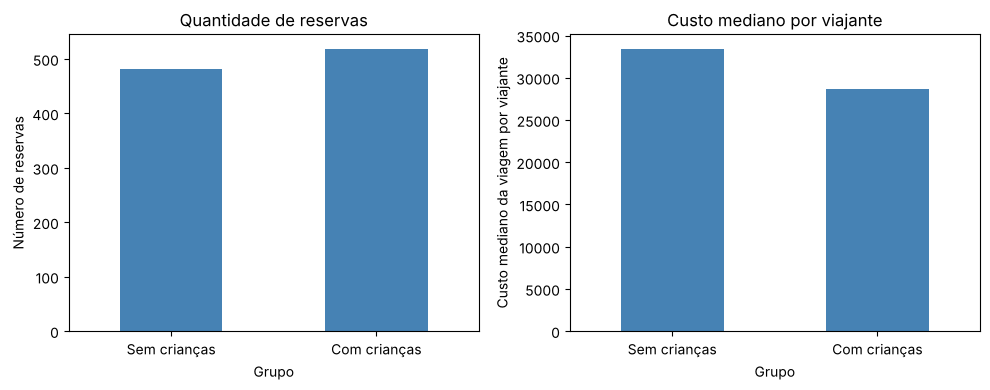

In [ ]:
# identificando reservas com crianças
dados['Com_criancas'] = dados['Number_of_Children'] > 0

# comparando características dos grupos
grupos = dados.groupby('Com_criancas').agg(
    Reservas=('Booking_ID', 'size'),
    Viajantes_medios=('Number_of_Travellers', 'mean'),
    Custo_total_mediano=('Total_Trip_Cost', 'median'),
    Custo_por_viajante=('Custo_por_viajante', 'median')
)
grupos = grupos.rename(index={False: 'Sem crianças', True: 'Com crianças'})

display(grupos.rename_axis(None).round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

grupos['Reservas'].plot(kind='bar', color='steelblue', ax=axes[0], rot=0)
axes[0].set_title('Quantidade de reservas')
axes[0].set_xlabel('Grupo')
axes[0].set_ylabel('Número de reservas')

grupos['Custo_por_viajante'].plot(kind='bar', color='steelblue', ax=axes[1], rot=0)
axes[1].set_title('Custo mediano por viajante')
axes[1].set_xlabel('Grupo')
axes[1].set_ylabel('Custo mediano da viagem por viajante')

plt.tight_layout()
plt.show()
